# Freddy: LATTE through the full regional ADCP survey

Choose `SOLO_TRANSECT` below (`F1` by default). Its shallowest accepted **inner** SOLO centre supplies LATTE's initial geographic origin; a rejected SOLO Gaussian radius does not disqualify that centre. LATTE then fits **all ADCP observations in the selected Freddy region at each measured depth**, without restricting them to a SOLO crossing time window. Each accepted LATTE inner centre seeds the next depth; rejected levels leave the previous accepted seed in place.

The overview maps the regional ADCP vectors at the selected SOLO seed depth, the relevant SOLO crossing tracks and their fitted shallowest centres. The remaining diagnostics and 2-D/3-D plots follow the Murphy LATTE and SOLO conventions. Freddy was sampled across several days and two visits, so spatial structure and temporal evolution can be aliased; the fitted depth profile is descriptive, not an instantaneous eddy section. “Surface” means the shallowest observed bin in the selected SOLO crossing. See [README.md](README.md) for the workflow and [transects.json](transects.json) for crossing definitions.

In [15]:
from pathlib import Path
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Rectangle

candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)

## Controls and SOLO starting centre

Edit `freddy_latte.json` for the regional footprint, fit settings and SOLO seed. Crossing windows and coordinate origins live in `transects.json`; rerun `freddy_solo.ipynb` and its export after changing them. This notebook uses every ADCP observation in the chosen region at each depth, without a crossing-time filter.


In [16]:
EDDY = "Freddy"
STUDY_DIR = OBSERVATIONS_DIR / "MNF_IN2015_V03_adcp_trawler"
CONFIG_PATH = STUDY_DIR / "freddy_latte.json"
CONFIG = json.loads(CONFIG_PATH.read_text())
TRANSECTS_PATH = STUDY_DIR / CONFIG["transects_config"]
BACKEND_PATH = Path(CONFIG["backend_path"])
DATA_PATH, transects, _ = esp.load_study(TRANSECTS_PATH, EDDY, load_adcp=False)
OUTPUT_DIR = DATA_PATH.parent / "outputs"
SOLO_RESULTS_PATH = OUTPUT_DIR / "freddy_solo_depth_fits.csv"
VISIT = CONFIG["visit"]  # Edit visit and seed in freddy_latte.json.
if VISIT not in ("visit1", "visit2"):
    raise ValueError("Regional Freddy LATTE takes one geographic visit at a time")
visit_ids = [f"F{i}" for i in (range(1, 8) if VISIT == "visit1" else range(8, 10))]
transects = transects.loc[visit_ids]
SOLO_TRANSECT = CONFIG["solo_transect_by_visit"][VISIT]
REGIONAL_VISIT = VISIT
FREDDY_BOUNDS = tuple(CONFIG["bounds_by_visit"][VISIT])
MAP_DEPTHS = tuple(CONFIG["map_depths_by_visit"][VISIT])
MIN_ATTENDANCE = CONFIG["min_attendance"]
FIT = CONFIG["fit"]
HALF_WIDTH_KM = CONFIG["half_width_km"]
VELOCITY_LIMIT = CONFIG["velocity_limit"]

if SOLO_TRANSECT not in transects.index:
    raise ValueError(f"SOLO_TRANSECT must be one of {list(transects.index)}")
solo = pd.read_csv(SOLO_RESULTS_PATH)
required = {"transect_id", "depth_m", "inner_valid", "xc_lon", "yc_lat"}
if not required.issubset(solo.columns):
    raise ValueError(f"Missing SOLO output columns: {required - set(solo.columns)}")
solo["inner_valid"] = solo.inner_valid.astype(str).str.lower().eq("true")
selected = solo.loc[solo.transect_id.eq(SOLO_TRANSECT) & solo.inner_valid].sort_values("depth_m")
if selected.empty:
    raise ValueError(f"No accepted SOLO inner centre for {SOLO_TRANSECT}")
SOLO_REF = selected.iloc[0]
ORIGIN_LON_LAT = (float(SOLO_REF.xc_lon), float(SOLO_REF.yc_lat))
west, east, south, north = FREDDY_BOUNDS
if not (west <= ORIGIN_LON_LAT[0] <= east and south <= ORIGIN_LON_LAT[1] <= north):
    raise ValueError("Selected SOLO centre lies outside the chosen Freddy region")
print(f"LATTE initial centre: {SOLO_TRANSECT} SOLO inner fit at {SOLO_REF.depth_m:g} m, "
      f"({ORIGIN_LON_LAT[0]:.5f}°E, {abs(ORIGIN_LON_LAT[1]):.5f}°S); "
      f"Gaussian status: {SOLO_REF.status}; regional footprint: {REGIONAL_VISIT}")


LATTE initial centre: F2 SOLO inner fit at 30.4 m, (153.15480°E, 32.61206°S); Gaussian status: outer_radius_limit; regional footprint: visit1; crossings: visit1


## Surface ADCP overview

Grey arrows sample all Freddy-region observations at the chosen SOLO seed depth. Coloured lines show crossings from the selected visit; crosses mark their shallowest accepted inner centres. The red frame is the regional selection. These vectors and tracks were sampled at different times.

selected_rows                                              34400
used_rows                                                  34400
unique_times                                                 851
start_utc                              2015-06-08 21:51:20+00:00
end_utc                                2015-06-16 10:42:37+00:00
depth_range_m                                      [18.5, 814.4]
missing_avg_qc                                             34400
zero_attendance_rows                                       14073
min_attendance                                              None
origin_lon_lat          (153.15480028983367, -32.61206114619023)
bounds_lon_lat                      (152.8, 153.5, -32.9, -32.3)
Name: LATTE selection audit, dtype: object

path                 /home/z5297792/ESP_zonodo/functions.py
sha256    8e4b06fe4c144f7a70671ee913b6d27784f9cdb587e9b0...
Name: ESP backend, dtype: object

,rows,times,shallowest_m,deepest_m,first_utc,last_utc
Datafile,,,,,,
in2015_v03_os150nb.nc,5729,227,18.5,290.5,2015-06-12 07:17:32+00:00,2015-06-16 10:42:37+00:00
in2015_v03_os75nb.nc,28671,624,30.4,814.4,2015-06-08 21:51:20+00:00,2015-06-11 21:21:43+00:00


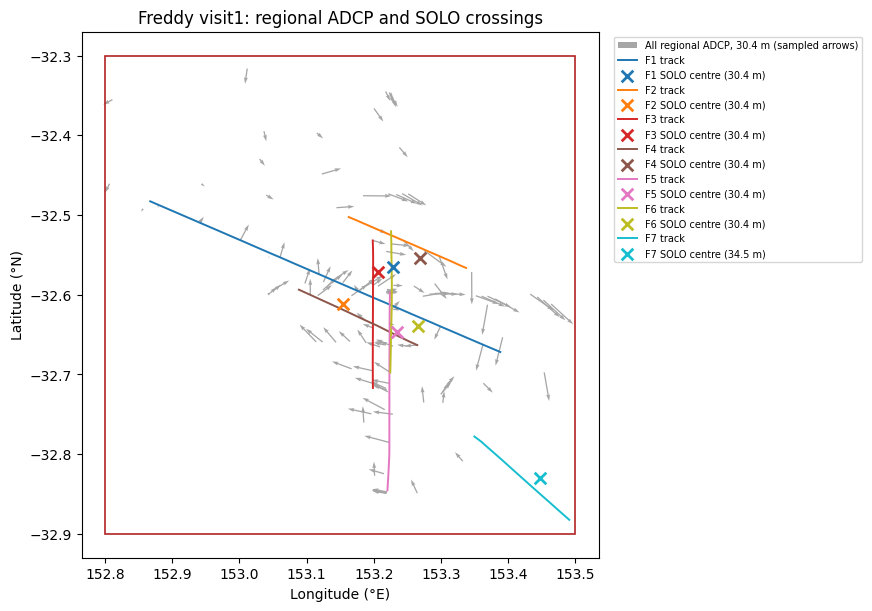

In [17]:
backend, backend_info = esp.load_backend(BACKEND_PATH)
data, coverage, audit = esp.load_observations(
    DATA_PATH, None, None, ORIGIN_LON_LAT,
    min_attendance=MIN_ATTENDANCE, bounds=FREDDY_BOUNDS)
display(pd.Series(audit, name="LATTE selection audit"))
display(pd.Series(backend_info, name="ESP backend"))
display(data.groupby("Datafile").agg(
    rows=("depth", "size"), times=("time", "nunique"),
    shallowest_m=("depth", "min"), deepest_m=("depth", "max"),
    first_utc=("time", "min"), last_utc=("time", "max")))

shown_depth = float(coverage.index[np.argmin(abs(coverage.index.to_numpy(float) - SOLO_REF.depth_m))])
visit_ids = [f"F{i}" for i in (range(1, 8) if REGIONAL_VISIT == "visit1" else range(8, 10))]
esp.plot_regional_track(
    data, transects, solo, FREDDY_BOUNDS, shown_depth=shown_depth,
    transect_ids=visit_ids,
    title=f"Freddy {REGIONAL_VISIT}: regional ADCP and SOLO crossings")
plt.show()

## LATTE fits from shallow to deep

Every depth uses the full regional sample at that depth. Accepted inner fits update the centre and ellipse used to select the next core, even if the Gaussian outer stage fails. The table retains failed levels and separates centre support from reconstruction support.

LATTE: 32/85 accepted inner fits; 32/85 accepted Gaussian reconstructions.
status
collinear_latte_sampling     3
insufficient_core            2
invalid_ellipse             48
ok                          32
Centre offsets reference the shallowest accepted fit: 30.4 m.
Reconstructed measured levels: 30.4–526.4 m (gaps retained).
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,core_spread_ratio,inner_R2,alpha,Rc_m,vector_R2
0,18.5,invalid_ellipse,39,18,False,False,0.0002,0.7874,NaN,NaN,NaN
1,26.5,invalid_ellipse,39,18,False,False,0.0002,0.8806,NaN,NaN,NaN
2,30.4,ok,624,444,True,True,0.7520,0.5797,1.7693,22202.3041,0.6056
3,34.5,invalid_ellipse,227,159,False,False,0.3295,0.4676,NaN,NaN,NaN
4,42.5,invalid_ellipse,227,159,False,False,0.3295,0.4793,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
80,750.4,invalid_ellipse,540,81,False,False,0.8674,0.1043,NaN,NaN,NaN
81,766.4,invalid_ellipse,529,77,False,False,0.8076,0.1089,NaN,NaN,NaN
82,782.4,insufficient_core,446,0,False,False,0.5971,0.0951,NaN,NaN,NaN
83,798.4,invalid_ellipse,226,37,False,False,0.3454,0.3112,NaN,NaN,NaN


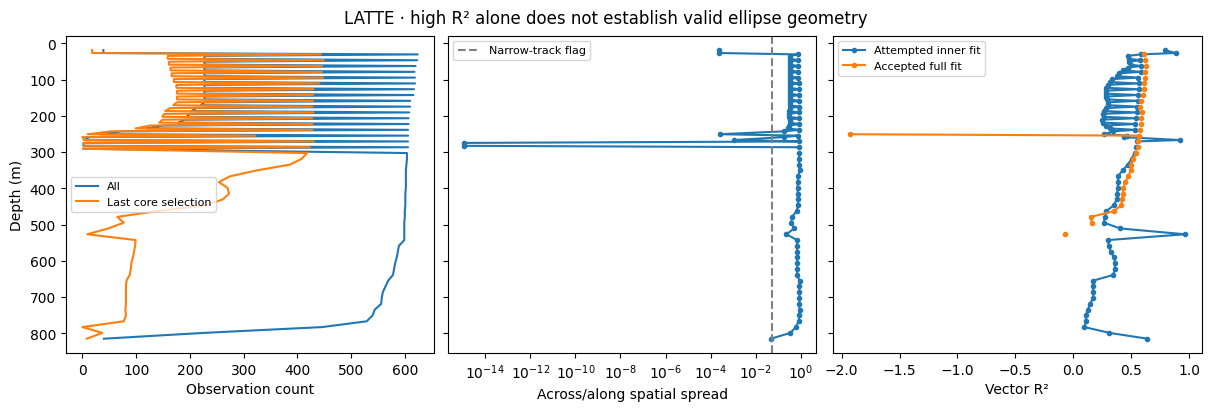

In [18]:
results, samples = esp.fit_depths(
    data, backend, "LATTE", depth_levels=coverage.index, **FIT)
esp.report(results)
columns = ["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
           "core_spread_ratio", "inner_R2", "alpha", "Rc_m", "vector_R2"]
with pd.option_context("display.max_rows", 60):
    display(results[columns].round(4))
esp.plot_diagnostics(results)
plt.show()

## Centre trajectory and reconstruction

Offsets are relative to LATTE's shallowest accepted centre; the chosen SOLO centre is only its initial seed. The horizontal maps, 3-D view and fixed zonal/meridional sections use the same helper and scales as the Murphy LATTE notebook. Reconstructed flow away from sampled points is model-based extrapolation. Levels from OS75 and OS150 are kept at their original measured depths, so their spatial and temporal support can differ; the deepest ADCP bin does not define the eddy bottom.

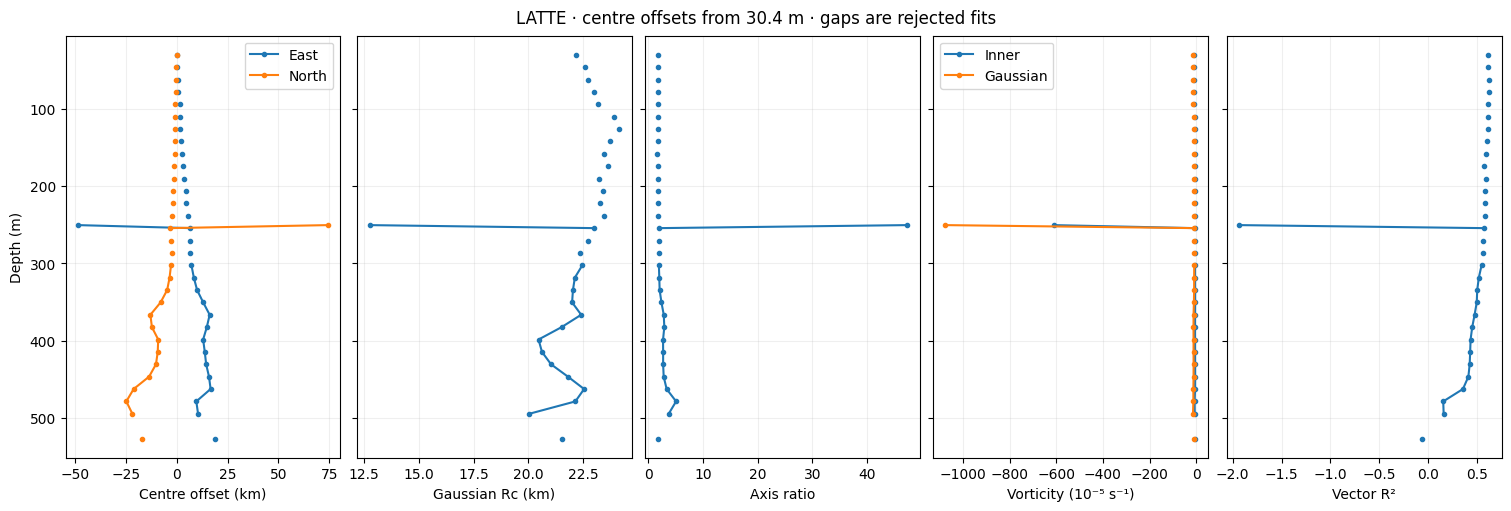

In [19]:
esp.plot_profiles(results)
plt.show()

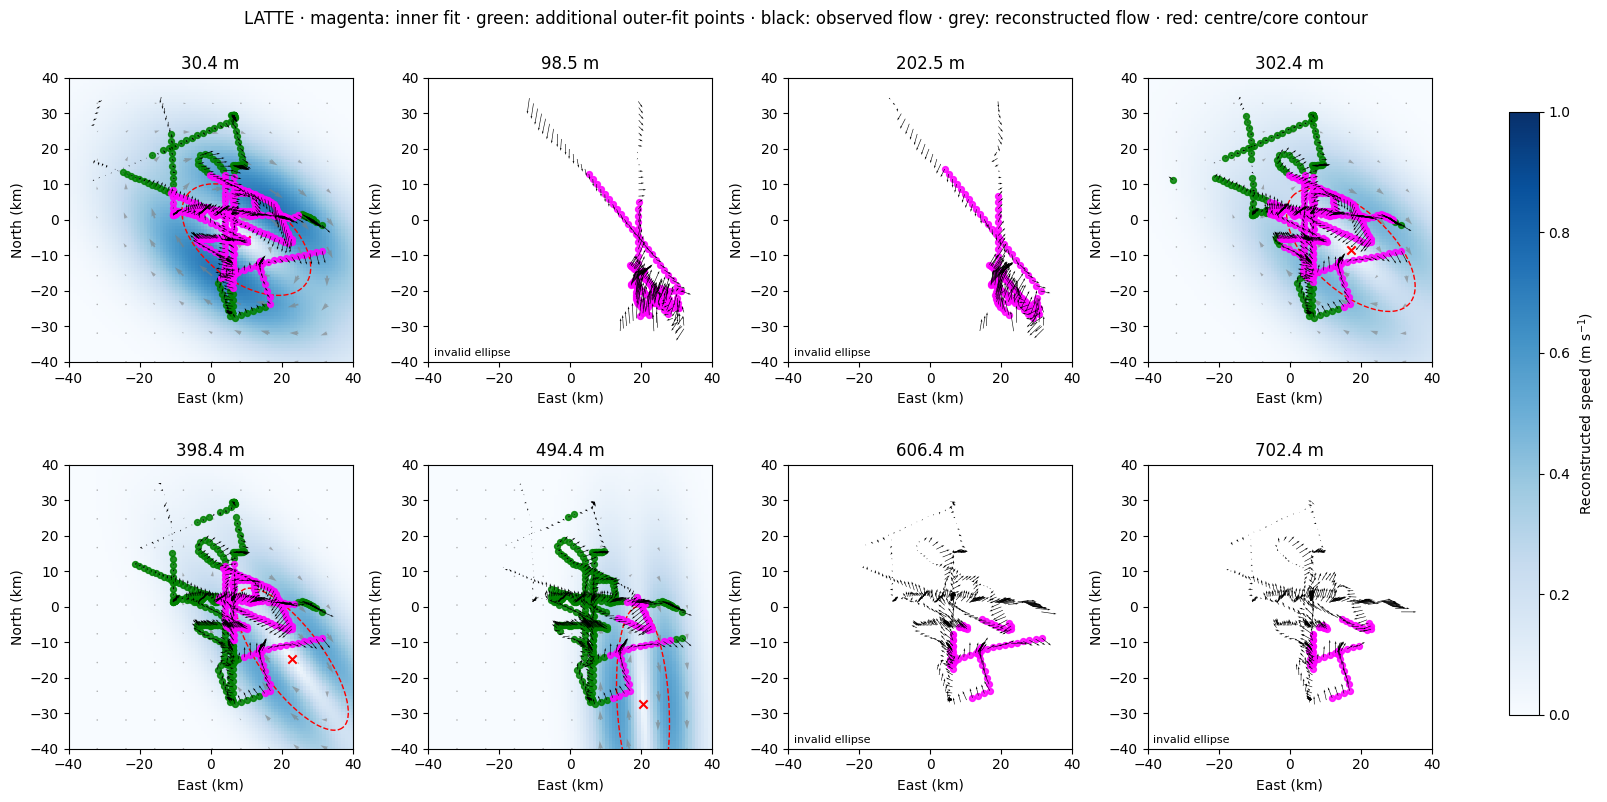

In [20]:
esp.plot_maps(results, samples, backend, depths=MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()

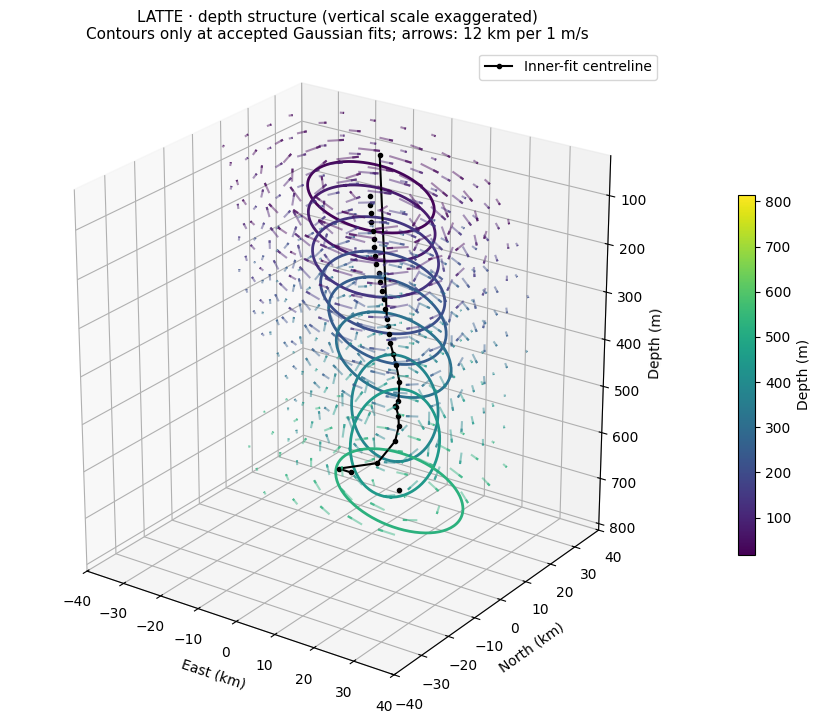

In [21]:
esp.plot_3d(results, backend, half_width_km=HALF_WIDTH_KM)
plt.show()

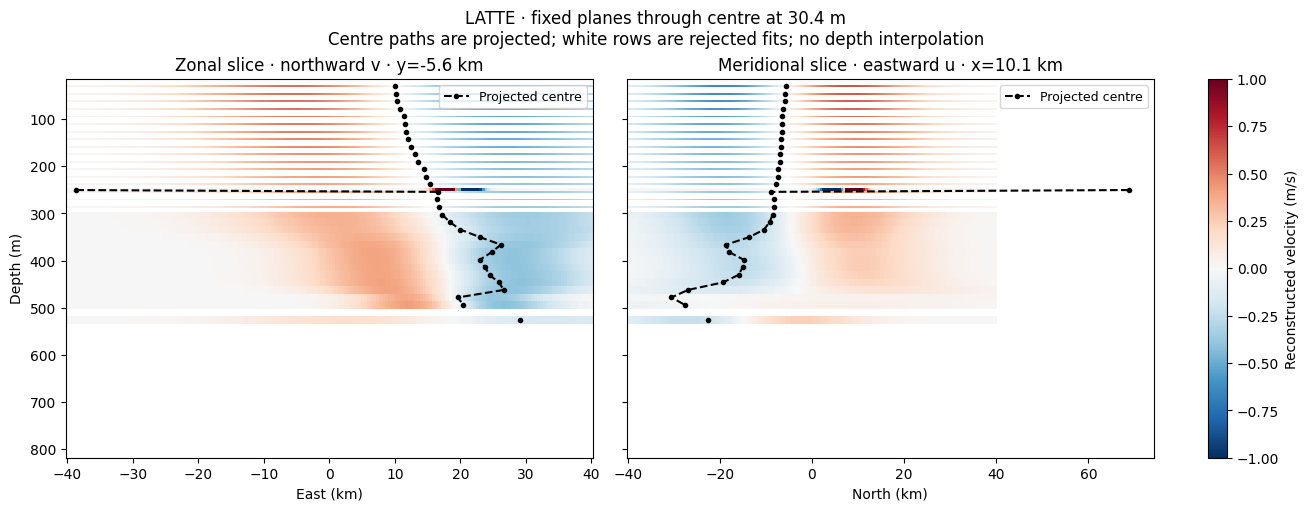

In [22]:
esp.plot_sections(results, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()

## Export to scratch

The CSV includes accepted and rejected depths. The companion JSON records the full regional selection, SOLO seed, visit, fit settings and backend fingerprint. Both stay beside this voyage's input CSV under `outputs/`.

In [23]:
SAVE_RESULTS = CONFIG["save_results"]
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    results.to_csv(OUTPUT_DIR / "freddy_latte_depth_fits.csv", index=False)
    provenance = dict(eddy=EDDY, method="LATTE", visit=REGIONAL_VISIT, selected_visits=VISIT,
                      bounds_lon_lat=FREDDY_BOUNDS,
                      data_path=str(DATA_PATH), config_path=str(CONFIG_PATH), transects_config_path=str(TRANSECTS_PATH),
                      backend=backend_info,
                      solo_results_path=str(SOLO_RESULTS_PATH),
                      solo_transect=SOLO_TRANSECT,
                      solo_surface_fit=SOLO_REF.to_dict(),
                      selection=audit, fit_settings=FIT)
    (OUTPUT_DIR / "freddy_latte_provenance.json").write_text(
        json.dumps(provenance, indent=2, default=str))
    print(f"Saved LATTE results to {OUTPUT_DIR}")

Saved LATTE results to /srv/scratch/z5297792/tilt_observation_data/MNF_IN2015_V03_adcp_trawler/outputs


## Along-track bin sensitivity

Set `along_track_bin_km` in `freddy_latte.json` to the widths to compare. The same binning and four-panel comparison as the SOLO notebooks are used, with LATTE fits and this notebook’s original fit settings. Each occupied projected along-track cell contributes one mean position and east/north velocity vector at each measured depth. All centre offsets reference the original shallowest accepted inner centre; `Rc` requires an accepted Gaussian fit and vorticity requires an accepted inner fit. This comparison does not change exported fits.

This uses the existing full regional selection, without a time filter. Bins project onto its shallowest-bin principal axis, so different ship passes at the same projected distance can be averaged together, including across sampling times. Interpret this as a regional sampling sensitivity rather than regular spacing along a single crossing.


In [ ]:
bin_data = data
bin_results = results
bin_coverage = coverage
bin_settings = FIT
bin_title = f"{EDDY} regional LATTE (SOLO seed {SOLO_TRANSECT})"

BIN_WIDTHS_KM = json.loads(CONFIG_PATH.read_text())["along_track_bin_km"]
if len(BIN_WIDTHS_KM) != len(set(BIN_WIDTHS_KM)):
    raise ValueError("along_track_bin_km must contain unique widths")
bin_fits = {"Original": bin_results}
bin_counts = [{"bin": "Original", "vectors": len(bin_data),
               "inner_depths": int(bin_results.inner_valid.sum()), "Rc_depths": int(bin_results.valid.sum())}]
for width_km in BIN_WIDTHS_KM:
    binned = esp.bin_solo_along_track(bin_data, width_km)
    fitted, _ = esp.fit_depths(binned, backend, "LATTE",
                               depth_levels=bin_coverage.index, **bin_settings)
    label = f"{width_km:g} km"
    bin_fits[label] = fitted
    bin_counts.append({"bin": label, "vectors": len(binned),
                       "inner_depths": int(fitted.inner_valid.sum()),
                       "Rc_depths": int(fitted.valid.sum())})
display(pd.DataFrame(bin_counts).set_index("bin"))
esp.plot_solo_binning_comparison(bin_fits, bin_title)
plt.show()
